# Phase 4 – Court Judgment Prediction (CJPE) on the **Transformer-XL + GQA** Phase-1 model

Decoder-only, causal **Transformer-XL + GQA** LM (8 blocks, d=768, 32 query heads / 8 KV heads, relative sinusoidal positions with `u`/`v` biases, post-LN, ≈76 M params) → binary outcome (0/1).

This notebook is the **Transformer-XL twin of `phase4_cjpe_gqla.ipynb`**. Data, cleaning, windowing, pooling, training loop, evaluation, threshold selection, submission packaging and the experiment list are the same; only the backbone (and the way each adaptation technique is attached to it) is Transformer-XL. The Transformer-XL classes are copied verbatim from your Phase-3 Transformer-XL notebook.

## What is carried over from the GQLA Phase-4 notebook (the fixes that matter)

| # | Problem found there | Treatment here |
|---|---|---|
| 1 | `method` leaking into the representation dict made every PEFT run secretly "frozen". | `REP` holds only representation keys; `run()` asserts `"method" not in REP` and asserts that non-frozen methods have more trainable params than the head. |
| 2 | Batch of 1 document, random windows, few docs per epoch → loss stayed ≈ ln 2. | Real mini-batches, deterministic windows, class-weighted loss, many more documents per epoch. |
| 3 | The outcome cue lives in the **tail** of the judgment; 24 sliding windows dilute it. | Views such as `"T0"`, `"T0,T1"`, `"H0,T0"`: only the windows that carry the signal. |
| 4 | Dev is 50/50 and closest to test. | `DEV_HOLDOUT` docs of dev = clean validation (threshold + epoch selection); the rest of dev is added to training (`DEV_REPEAT`×). |
| 5 | Mean pooling dilutes keyword cues in a causal model. | Per window: **last-token + mean + max** pooling (3·768 dims). |

## What is specific to Transformer-XL

| Topic | GQLA notebook | This notebook |
|---|---|---|
| Backbone | 10 pre-LN blocks, d=512, decoupled RoPE | 8 **post-LN** blocks, d=768, Transformer-XL relative attention, GQA 32q/8kv |
| Window feature | 3·512 = 1 536 dims | 3·768 = 2 304 dims |
| LoRA / LoRMA+ targets | `W_DQ, W_UQ, W_DKV, W_UK, W_UV, W_O`, FFN | `q_proj, k_proj, v_proj, out_proj`, `ffn.0`, `ffn.3` (`r_proj`, the positional projection, stays frozen) |
| IA³ | scales `W_UK`, `W_UV`, FFN hidden | scales `k_proj`, `v_proj` outputs and the FFN hidden activations (`ffn.3` input) |
| BitFit | FFN + LayerNorm biases | same: `ffn.0/3` biases, `norm1/norm2` and `final_norm` biases (attention projections are bias-free) |
| Prefix tuning | – | **new (X6)**: learnable per-layer "virtual memory" fed through Transformer-XL's own `memory` argument |
| KD student | bottom-5 blocks | **layer-strided** 4-block student (blocks 0, 2, 5, 7), as in your Phase-3 TXL notebook |
| Segment recurrence (memory) | – | **not used**: every window is encoded independently (memory is only used by prefix tuning). Say so in the report. |

Small robustness additions (useful when Colab disconnects): the B1 teacher is **saved to disk** and reloaded for KD; `run()` skips experiments that already finished (set `FORCE_RERUN=True` to redo); the tokenisation cache of the GQLA notebook is reused when present (same tokenizer ⇒ same ids; it is validated by document ids + config before use).

## Honest expectations
I could **not** run this (no GPU / torch in my environment). Torch-side code is untested; the pure-Python parts (tokenizer wrapper, windowing, metrics, threshold search) were unit-tested. **0.7 is a target, not a guarantee.** Run Section 4 (CPU) first if you have not already: it measures how much outcome signal a plain lexical model finds in each region of the document. That probe is a diagnostic only — it is not Phase-1 model output and must **not** be submitted (every submission must start from your Phase-1 model).

## Order of play
1. Sections 1–5 (setup, data, tokenise, probe, load Transformer-XL). 2. `benchmark()` → docs/s, then set `docs_per_epoch`. 3. `SMOKE_TEST` once. 4. B1 full FT first (it is also the KD teacher). 5. B2…B6, submit each zip; keep ≥6 *different techniques*.

> Course policy reminder (§17.5): LLM help is not allowed for hyperparameter tuning or for result analysis/conclusions, and the LLM declaration is mandatory. The hyper-parameters below are **inherited defaults from the GQLA notebook, not tuned values** — choose and justify your own. Declare the help you used for this notebook, be ready to explain every cell in the viva, and write the analysis yourself.

## 1. Config

In [ ]:
import os, sys, re, json, random, unicodedata, zipfile, time, math, pickle, gc, copy
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED)
SMOKE_TEST = False          # True -> tiny subsets, 1 epoch; zips are NOT submittable
FORCE_RERUN = False         # False -> run() skips experiments whose submission.zip + registry row already exist
RUN_LEXICAL_PROBE = True    # Section 4 is identical to the GQLA notebook (same tokenizer + data): set False if you already ran it there

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/Phase4_CJPE_TXL"
else:
    OUTPUT_DIR = "./phase4_txl_outputs"
if SMOKE_TEST: OUTPUT_DIR += "_smoke"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DATA_DIR = "./phase4_cjpe_data"; os.makedirs(DATA_DIR, exist_ok=True)

# ---- EDIT: Phase-1 Transformer-XL + GQA artefacts (same paths as your Phase-3 TXL notebook) ----
P1_DIR = "/content/drive/MyDrive/CS781/Capstone-Project/legal_dataset_cache"
CHECKPOINT_PATH = os.path.join(P1_DIR, "transformer_xl_gqa_checkpoints", "best_model_transformer_xl_gqa-small.pt")
TOKENIZER_PATH  = os.path.join(P1_DIR, "final_bpe_en.json")
# Optional: tokenisation cache written by the GQLA Phase-4 notebook (same tokenizer => valid; checked against doc ids + config before use)
GQLA_TOK_CACHE  = "/content/drive/MyDrive/Phase4_CJPE_GQLA/tok_cache_gqla.pkl"

# Must match the Phase-1 Transformer-XL + GQA run exactly (identical to your Phase-3 TXL notebook)
MODEL_CONFIG = {"vocab_size": 32768, "d_model": 768, "num_layers": 8, "num_query_heads": 32, "num_kv_heads": 8,
                "memory_length": 128, "dropout": 0.1}

# NEVER hard-code the HF token. Use Colab secrets or the environment.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None and IN_COLAB:
    try:
        from google.colab import userdata; HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception: pass

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint as grad_checkpoint
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
if DEVICE.type == "cuda": torch.cuda.manual_seed_all(SEED); print("GPU:", torch.cuda.get_device_name(0))
print("Output dir:", OUTPUT_DIR, "| HF token set:", HF_TOKEN is not None, "| SMOKE_TEST:", SMOKE_TEST)

Mounted at /content/drive
GPU: Tesla T4
Output dir: /content/drive/MyDrive/Phase4_CJPE_TXL | HF token set: True | SMOKE_TEST: False


## 2. Data, cleaning, metrics, logger, submission utilities
Identical to the GQLA Phase-4 notebook (same cleaning, same macro-F1 / threshold search, same submission validation).

In [ ]:
from huggingface_hub import hf_hub_download
REPO_ID = "Exploration-Lab/CS-781-Capstone"
FILES = {"train": "Phase_4_CJPE/Train/train.json", "dev": "Phase_4_CJPE/Train/dev.json", "test": "Phase_4_CJPE/Test/test.json"}
raw_data = {}
for k, fn in FILES.items():
    p = hf_hub_download(repo_id=REPO_ID, filename=fn, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
    raw_data[k] = json.load(open(p, encoding="utf-8")); print(k, len(raw_data[k]))

def norm(x):
    s = unicodedata.normalize("NFKC", "" if x is None else str(x))
    return re.sub(r"\s+", " ", s.replace("\u00a0", " ")).strip()

def clean_split(raw, name, labeled):
    out = []
    for item in raw:
        rid = item["id"]; text = item["text"]
        if isinstance(text, (list, tuple)): text = " ".join(map(str, text))
        text = norm(text)
        if not text:
            if labeled: continue
            text = "."
        d = {"id": str(rid), "rid": rid, "text": text}
        if labeled:
            lab = item["label"]
            if isinstance(lab, (list, tuple)) and len(lab) == 1: lab = lab[0]
            lab = int(float(lab)); assert lab in (0, 1)
            d["label"] = lab
        out.append(d)
    return out

cleaned = {k: clean_split(raw_data[k], k, k != "test") for k in ["train", "dev", "test"]}
assert len(cleaned["test"]) == len(raw_data["test"]), "test docs dropped!"
assert len({d["id"] for d in cleaned["test"]}) == len(cleaned["test"]), "duplicate test ids"
print({k: len(v) for k, v in cleaned.items()})
for sp in ["train", "dev"]:
    c = Counter(d["label"] for d in cleaned[sp]); print(sp, dict(c), "frac_1 = %.3f" % (c[1] / sum(c.values())))

def cj_scores(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], average="macro", zero_division=0)
    _, _, fc, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], average=None, zero_division=0)
    return {"P": float(p), "R": float(r), "F1": float(f), "accuracy": float(np.mean(np.array(y_true) == np.array(y_pred))),
            "F1_c0": float(fc[0]), "F1_c1": float(fc[1])}

def tune_threshold(y_true, probs, grid=None):
    """Global threshold on P(1) maximising macro-F1; ties -> closest to 0.5."""
    grid = np.linspace(0.05, 0.95, 91) if grid is None else grid
    y_true, probs = np.asarray(y_true), np.asarray(probs)
    best_t, best_f = 0.5, -1.0
    for t in grid:
        f = cj_scores(y_true, (probs >= t).astype(int))["F1"]
        if f > best_f + 1e-12 or (abs(f - best_f) <= 1e-12 and abs(t - 0.5) < abs(best_t - 0.5)): best_t, best_f = float(t), f
    return best_t, best_f

def plot_confusion(y_true, y_pred, title, path=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1]); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.2f})", ha="center", va="center", fontsize=8)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(title, fontsize=8)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150)
    plt.show()

REGISTRY_PATH = os.path.join(OUTPUT_DIR, "experiment_registry.csv")
registry = pd.read_csv(REGISTRY_PATH).to_dict("records") if os.path.exists(REGISTRY_PATH) else []
def log_experiment(name, technique, trainable, total, scores, extra):
    row = {"name": name, "technique": technique, "trainable_params": trainable, "total_params": total, **extra,
           "time": time.strftime("%Y-%m-%d %H:%M")}
    row.update({k: round(v, 4) if isinstance(v, float) else v for k, v in scores.items()})
    registry.append(row); pd.DataFrame(registry).to_csv(REGISTRY_PATH, index=False); return row

def build_submission(docs, probs, thr):
    return [{"id": d["rid"], "pred": int(probs[d["id"]] >= thr)} for d in docs]

def validate_submission(sub):
    expected = [str(d["rid"]) for d in cleaned["test"]]; got = [str(x["id"]) for x in sub]
    assert isinstance(sub, list) and len(got) == len(set(got)), "not a list / duplicate ids"
    assert not (set(expected) - set(got)), "missing ids"; assert not (set(got) - set(expected)), "unknown ids"
    for x in sub:
        assert set(x) == {"id", "pred"} and type(x["pred"]) is int and x["pred"] in (0, 1), x
    return True

def package_submission(sub, zip_path):
    validate_submission(sub)
    jp = os.path.join(os.path.dirname(zip_path), "prediction.json")
    json.dump(sub, open(jp, "w", encoding="utf-8"), ensure_ascii=False)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z: z.write(jp, arcname="prediction.json")
    with zipfile.ZipFile(zip_path) as z: assert z.namelist() == ["prediction.json"]
    return zip_path

Phase_4_CJPE/Train/train.json: reconstructing file:   0%|          |  0.00B /  737MB            

Phase_4_CJPE/Train/train.json: downloading bytes:           |  0.00B            

train 37387


Phase_4_CJPE/Train/dev.json: reconstructing file:   0%|          |  0.00B / 45.0MB            

Phase_4_CJPE/Train/dev.json: downloading bytes:           |  0.00B            

dev 1988


Phase_4_CJPE/Test/test.json: reconstructing file:   0%|          |  0.00B / 35.3MB            

Phase_4_CJPE/Test/test.json: downloading bytes:           |  0.00B            

test 1517
{'train': 37387, 'dev': 1988, 'test': 1517}
train {0: 22067, 1: 15320} frac_1 = 0.410
dev {0: 994, 1: 994} frac_1 = 0.500


## 3. Phase-1 tokenizer and tokenisation (documents are trimmed to first 2 048 + last 6 144 tokens: the tail is what matters)

In [ ]:
import os, re, json, heapq, collections

try:
    import psutil
    _PROC = psutil.Process(os.getpid())
except Exception:
    _PROC = None

def _ram_gb():
    return _PROC.memory_info().rss / (1024 ** 3) if _PROC else 0.0

WORD_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)
_WORKER = None
def _init_worker(tok):
    global _WORKER
    _WORKER = tok
def _encode_chunk(args):
    texts, add_special = args
    return [_WORKER.encode(t, add_special) for t in texts]

class BPETokenizer:
    _HEAP_THRESHOLD = 24
    _CACHE_LIMIT = 500_000

    def __init__(self, vocab_size, end_marker="</w>", reserved_tokens=None):
        self.vocab_size = vocab_size
        self.end_marker = end_marker
        self.reserved_tokens = reserved_tokens if reserved_tokens is not None else ["<pad>", "<unk>", "<s>", "</s>"]
        self.itos = list(self.reserved_tokens)
        self.stoi = {t: i for i, t in enumerate(self.reserved_tokens)}
        self.merges = {}
        self._ready = False
        self._cache = {}

    @staticmethod
    def from_json(path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = BPETokenizer(vocab_size=data["vocab_size"], end_marker=data.get("end_marker", "</w>"),
                            reserved_tokens=data.get("reserved_tokens", ["<pad>", "<unk>", "<s>", "</s>"]))
        tok.itos = data["itos"]; tok.stoi = data["stoi"]
        tok.merges = {tuple(p): r for p, r in data["merges"]}
        tok._ready = False; tok._cache = {}
        return tok

    def _prepare_inference(self):
        if self._ready: return
        self._byte_ids = [self.stoi[bytes([b]).decode("latin-1")] for b in range(256)]
        self._first_merge_id = len(self.itos) - len(self.merges)
        self._end_id = self.stoi.get(self.end_marker, self.stoi["<unk>"])
        self._bos = self.stoi["<s>"]; self._eos = self.stoi["</s>"]
        base = self._first_merge_id
        for (a, b), r in self.merges.items():
            if self.itos[base + r] != self.itos[a] + self.itos[b]:
                raise ValueError("Merge/vocab mismatch: cannot infer merge ids from ranks.")
        self._M = len(self.itos); M = self._M
        self._ranks = {a * M + b: r for (a, b), r in self.merges.items()}
        self._cache = {}; self._ready = True

    def _merge_small(self, ids):
        get, M, base = self._ranks.get, self._M, self._first_merge_id
        while len(ids) > 1:
            best, best_i = None, -1
            for i in range(len(ids) - 1):
                r = get(ids[i] * M + ids[i + 1])
                if r is not None and (best is None or r < best):
                    best, best_i = r, i
            if best is None: break
            a, b, new = ids[best_i], ids[best_i + 1], base + best
            out, i, n = [], 0, len(ids)
            while i < n:
                if i < n - 1 and ids[i] == a and ids[i + 1] == b:
                    out.append(new); i += 2
                else:
                    out.append(ids[i]); i += 1
            ids = out
        return ids

    def _merge_heap(self, ids):
        get, M, base = self._ranks.get, self._M, self._first_merge_id
        n = len(ids)
        nxt = list(range(1, n + 1)); nxt[-1] = -1
        prv = list(range(-1, n - 1)); alive = [True] * n
        heap = []
        for i in range(n - 1):
            r = get(ids[i] * M + ids[i + 1])
            if r is not None: heap.append((r, i))
        heapq.heapify(heap)
        while heap:
            r, i = heapq.heappop(heap)
            if not alive[i]: continue
            j = nxt[i]
            if j == -1 or get(ids[i] * M + ids[j]) != r: continue
            ids[i] = base + r; alive[j] = False
            k = nxt[j]; nxt[i] = k
            if k != -1: prv[k] = i
            p = prv[i]
            if p != -1:
                r2 = get(ids[p] * M + ids[i])
                if r2 is not None: heapq.heappush(heap, (r2, p))
            if k != -1:
                r2 = get(ids[i] * M + ids[k])
                if r2 is not None: heapq.heappush(heap, (r2, i))
        return [ids[i] for i in range(n) if alive[i]]

    def _bpe_word(self, word):
        hit = self._cache.get(word)
        if hit is not None: return hit
        ids = [self._byte_ids[b] for b in word.encode("utf-8")]
        ids.append(self._end_id)
        ids = self._merge_small(ids) if len(ids) <= self._HEAP_THRESHOLD else self._merge_heap(ids)
        result = tuple(ids)
        if len(self._cache) < self._CACHE_LIMIT: self._cache[word] = result
        return result

    def encode(self, text, add_special_tokens=True):
        self._prepare_inference()
        out = [self._bos] if add_special_tokens else []
        extend = out.extend; cache_get = self._cache.get; bpe = self._bpe_word
        for w in WORD_RE.findall(text):
            t = cache_get(w)
            if t is None: t = bpe(w)
            extend(t)
        if add_special_tokens: out.append(self._eos)
        return out

    def encode_batch(self, texts, add_special_tokens=True, num_workers=None, chunk_size=256):
        """Encode many documents, optionally across processes (fork only)."""
        self._prepare_inference()
        texts = list(texts)
        if num_workers is None: num_workers = os.cpu_count() or 1
        if num_workers <= 1 or len(texts) < 2 * chunk_size:
            return [self.encode(t, add_special_tokens) for t in texts]
        import multiprocessing as mp
        chunks = [(texts[i:i + chunk_size], add_special_tokens) for i in range(0, len(texts), chunk_size)]
        ctx = mp.get_context("fork")
        with ctx.Pool(num_workers, initializer=_init_worker, initargs=(self,)) as pool:
            results = list(pool.imap(_encode_chunk, chunks))
        return [ids for chunk in results for ids in chunk]

    def decode(self, token_ids):
        self._prepare_inference()
        filtered_ids = [tid for tid in token_ids if self.itos[tid] not in self.reserved_tokens]
        decoded_text = "".join([self.itos[tid] for tid in filtered_ids]).replace(self.end_marker, " ")
        return decoded_text.strip()

if not os.path.isfile(TOKENIZER_PATH): raise FileNotFoundError(TOKENIZER_PATH)
tokenizer = BPETokenizer.from_json(TOKENIZER_PATH)
PAD_ID = tokenizer.stoi.get("<pad>", 0); BOS_ID = tokenizer.stoi.get("<s>", 2); EOS_ID = tokenizer.stoi.get("</s>", 3)
VOCAB_SIZE = len(tokenizer.itos)
assert VOCAB_SIZE == MODEL_CONFIG["vocab_size"], "tokenizer vocab must match the Phase-1 checkpoint"
print("vocab", VOCAB_SIZE, "| PAD/BOS/EOS", PAD_ID, BOS_ID, EOS_ID)

vocab 32768 | PAD/BOS/EOS 0 2 3


In [ ]:
KEEP_HEAD, KEEP_TAIL, MAX_CHARS = 2048, 6144, 120_000
CACHE_PATH = os.path.join(OUTPUT_DIR, "tok_cache_txl.pkl")
cache = {}
if not SMOKE_TEST:
    for _p in (CACHE_PATH, GQLA_TOK_CACHE):        # own cache first, then the GQLA notebook's (same tokenizer; validated per split below)
        if os.path.exists(_p):
            try: cache = pickle.load(open(_p, "rb")); print("token cache <-", _p, list(cache)); break
            except Exception as e: print("unreadable cache", _p, e)

def trim_ht(x, head, tail):
    return x if len(x) <= head + tail else x[:head] + x[-tail:]

def tokenise_split(name, docs):
    sig = [d["id"] for d in docs]; c = cache.get(name)
    if c and c["sig"] == sig and c["cfg"] == (KEEP_HEAD, KEEP_TAIL, MAX_CHARS, VOCAB_SIZE): return c["arrays"]
    arrays, t0 = [], time.time()
    for s in range(0, len(docs), 256):
        texts = [t if len(t) <= MAX_CHARS else t[:MAX_CHARS // 4] + t[-(MAX_CHARS - MAX_CHARS // 4):] for t in (d["text"] for d in docs[s:s + 256])]
        ids = tokenizer.encode_batch(texts, add_special_tokens=False, chunk_size=8)
        arrays += [np.asarray(trim_ht(x, KEEP_HEAD, KEEP_TAIL), dtype=np.int32) for x in ids]
        print(f"  {name}: {len(arrays)}/{len(docs)} ({time.time()-t0:.0f}s)", end="\r")
    print(); cache[name] = {"sig": sig, "cfg": (KEEP_HEAD, KEEP_TAIL, MAX_CHARS, VOCAB_SIZE), "arrays": arrays}
    pickle.dump(cache, open(CACHE_PATH, "wb")); return arrays

if SMOKE_TEST:
    rs = random.Random(SEED)
    cleaned["train"] = rs.sample(cleaned["train"], 96); cleaned["dev"] = rs.sample(cleaned["dev"], 48); cleaned["test"] = cleaned["test"][:16]
for sp in ["train", "dev", "test"]:
    for d, a in zip(cleaned[sp], tokenise_split(sp, cleaned[sp])): d["ids"], d["n_tok"] = a, len(a)
    for d in cleaned[sp]: d["text"] = None          # free RAM
    n = pd.Series([d["n_tok"] for d in cleaned[sp]])
    print(sp, "tokens/doc", n.describe(percentiles=[.25, .5, .75, .95]).round(0).to_dict())

# dev -> clean validation hold-out (stratified) + extra training data (dev is closer to test than train is)
DEV_HOLDOUT, DEV_REPEAT = (24 if SMOKE_TEST else 1000), 3
rs = random.Random(SEED); by = defaultdict(list)
for d in cleaned["dev"]: by[d["label"]].append(d)
dev_val = []
for lab, ds in by.items(): dev_val += rs.sample(ds, round(DEV_HOLDOUT * len(ds) / len(cleaned["dev"])))
_vid = {d["id"] for d in dev_val}
DATA = {"train": cleaned["train"], "dev_full": cleaned["dev"], "dev_val": dev_val,
        "dev_train": [d for d in cleaned["dev"] if d["id"] not in _vid], "test": cleaned["test"]}
print({k: len(v) for k, v in DATA.items()})

  train: 37387/37387 (195s)
train tokens/doc {'count': 37387.0, 'mean': 3282.0, 'std': 2460.0, 'min': 53.0, '25%': 1288.0, '50%': 2689.0, '75%': 4760.0, '95%': 8192.0, 'max': 8192.0}
  dev: 1988/1988 (11s)
dev tokens/doc {'count': 1988.0, 'mean': 4016.0, 'std': 2256.0, 'min': 193.0, '25%': 2194.0, '50%': 3468.0, '75%': 5556.0, '95%': 8192.0, 'max': 8192.0}
  test: 1517/1517 (9s)
test tokens/doc {'count': 1517.0, 'mean': 4088.0, 'std': 2279.0, 'min': 96.0, '25%': 2281.0, '50%': 3579.0, '75%': 5648.0, '95%': 8192.0, 'max': 8192.0}
{'train': 37387, 'dev_full': 1988, 'dev_val': 1000, 'dev_train': 464, 'test': 1517}


## 4. CPU diagnostic – *where in a judgment is the outcome signal?* (not a submission)
Bag of token-id unigrams + hashed bigrams → TF-IDF → logistic regression, one region at a time, scored on `dev_val`. It depends only on tokenizer + data, so it gives the **same numbers as in the GQLA notebook** (skip it with `RUN_LEXICAL_PROBE = False` if you already have them). Interpret it yourself.

In [ ]:
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.linear_model import LogisticRegression
NB = 1 << 20
def region_ids(d, region):
    a, n = d["ids"], d["n_tok"]
    if region == "head512": return a[:512]
    if region.startswith("tail"):
        k = int(region[4:]); return a[max(0, n - k):]
    if region == "T1_512": return a[max(0, n - 1024): max(0, n - 512)]
    if region == "T2_512": return a[max(0, n - 1536): max(0, n - 1024)]
    if region == "middle": return a[n // 2 - 256: n // 2 + 256]
    if region == "whole": return a
    raise ValueError(region)
def bow(docs, region):
    rows, cols, vals = [], [], []
    for i, d in enumerate(docs):
        x = region_ids(d, region).astype(np.int64)
        feats = np.concatenate([x, (x[:-1] * 32768 + x[1:]) % NB + 32768]) if len(x) > 1 else x
        u, c = np.unique(feats, return_counts=True); rows += [i] * len(u); cols += u.tolist(); vals += c.tolist()
    return sp.csr_matrix((vals, (rows, cols)), shape=(len(docs), NB + 32768), dtype=np.float32)
def lexical_probe(regions, n_train=20000):
    tr = random.Random(SEED).sample(DATA["train"], min(n_train, len(DATA["train"]))); va = DATA["dev_val"]
    ytr, yva = [d["label"] for d in tr], [d["label"] for d in va]; rows = []
    for r in regions:
        Xtr, Xva = bow(tr, r), bow(va, r); tf = TfidfTransformer(sublinear_tf=True).fit(Xtr)
        lr = LogisticRegression(C=2.0, max_iter=300, class_weight="balanced").fit(tf.transform(Xtr), ytr)
        p = lr.predict_proba(tf.transform(Xva))[:, 1]; sc = cj_scores(yva, (p >= 0.5).astype(int))
        rows.append({"region": r, "F1@0.5": round(sc["F1"], 4), "F1_tuned": round(tune_threshold(yva, p)[1], 4)}); print(rows[-1])
    return pd.DataFrame(rows)
probe_df = lexical_probe(["head512", "middle", "tail256", "tail512", "T1_512", "T2_512", "tail1024", "whole"] if not SMOKE_TEST else ["tail512"]) if RUN_LEXICAL_PROBE else None
probe_df

{'region': 'head512', 'F1@0.5': 0.4541, 'F1_tuned': 0.5367}
{'region': 'middle', 'F1@0.5': 0.5475, 'F1_tuned': 0.5748}
{'region': 'tail256', 'F1@0.5': 0.5986, 'F1_tuned': 0.6208}
{'region': 'tail512', 'F1@0.5': 0.6066, 'F1_tuned': 0.6367}
{'region': 'T1_512', 'F1@0.5': 0.6173, 'F1_tuned': 0.6173}
{'region': 'T2_512', 'F1@0.5': 0.5671, 'F1_tuned': 0.5785}
{'region': 'tail1024', 'F1@0.5': 0.6342, 'F1_tuned': 0.6507}
{'region': 'whole', 'F1@0.5': 0.6345, 'F1_tuned': 0.641}


,region,F1@0.5,F1_tuned
0,head512,0.4541,0.5367
1,middle,0.5475,0.5748
2,tail256,0.5986,0.6208
3,tail512,0.6066,0.6367
4,T1_512,0.6173,0.6173
5,T2_512,0.5671,0.5785
6,tail1024,0.6342,0.6507
7,whole,0.6345,0.6410


## 5. Load the Phase-1 Transformer-XL + GQA model (classes copied verbatim from your Phase-3 TXL notebook)

In [ ]:
import math

class TransformerXLRelativePositionalEncoding(nn.Module):
    def __init__(self, d_model: int, base: float = 10000.0):
        super().__init__()
        if d_model % 2:
            raise ValueError("d_model must be even")
        self.d_model = d_model
        inv_freq = 1.0 / (base ** (torch.arange(0, d_model, 2, dtype=torch.float32) / d_model))
        self.register_buffer("inv_freq", inv_freq, persistent=False)

    def forward(self, query_length: int, key_length: int, device=None):
        if key_length <= 0:
            raise ValueError("key_length must be positive")
        if device is None:
            device = self.inv_freq.device
        pos_seq = torch.arange(key_length - 1, -1, -1, dtype=torch.float32, device=device)
        sinusoid_inp = torch.outer(pos_seq, self.inv_freq.to(device))
        return torch.cat([sinusoid_inp.sin(), sinusoid_inp.cos()], dim=-1)

class TransformerXLGQAAttention(nn.Module):
    def __init__(self, d_model, num_query_heads, num_kv_heads, dropout=0.0):
        super().__init__()
        if d_model % num_query_heads != 0:
            raise ValueError("d_model must be divisible by num_query_heads")
        if num_query_heads % num_kv_heads != 0:
            raise ValueError("num_query_heads must be divisible by num_kv_heads")
        self.d_model = d_model
        self.num_query_heads = num_query_heads
        self.num_kv_heads = num_kv_heads
        self.head_dim = d_model // num_query_heads
        self.group_size = num_query_heads // num_kv_heads

        self.q_proj = nn.Linear(d_model, num_query_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, num_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, num_kv_heads * self.head_dim, bias=False)
        self.r_proj = nn.Linear(d_model, num_kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

        self.u = nn.Parameter(torch.zeros(num_query_heads, self.head_dim))
        self.v = nn.Parameter(torch.zeros(num_query_heads, self.head_dim))
        nn.init.normal_(self.u, std=0.02)
        nn.init.normal_(self.v, std=0.02)
        self.dropout = nn.Dropout(dropout)

    def _q_heads(self, x):
        B, T, _ = x.shape
        return x.view(B, T, self.num_query_heads, self.head_dim).transpose(1, 2)

    def _kv_heads(self, x):
        B, T, _ = x.shape
        return x.view(B, T, self.num_kv_heads, self.head_dim).transpose(1, 2)

    def _expand_kv(self, x):
        B, H, T, D = x.shape
        return x.unsqueeze(2).expand(B, H, self.group_size, T, D).reshape(B, self.num_query_heads, T, D)

    @staticmethod
    def _rel_shift(x):
        B, H, Q, K = x.shape
        zero = torch.zeros((B, H, Q, 1), dtype=x.dtype, device=x.device)
        x = torch.cat([zero, x], dim=-1)
        x = x.view(B, H, K + 1, Q)
        x = x[:, :, 1:].view(B, H, Q, K)
        return x

    @staticmethod
    def _causal_mask(query_length, key_length, device):
        memory_length = key_length - query_length
        return torch.triu(torch.ones((query_length, key_length), dtype=torch.bool, device=device),
                           diagonal=memory_length + 1)

    def forward(self, x, memory=None, relative_position=None):
        B, Q, _ = x.shape
        if memory is not None and memory.size(1) > 0:
            kv_input = torch.cat([memory, x], dim=1)
        else:
            kv_input = x
        K = kv_input.size(1)

        q = self._q_heads(self.q_proj(x))
        k = self._expand_kv(self._kv_heads(self.k_proj(kv_input)))
        v = self._expand_kv(self._kv_heads(self.v_proj(kv_input)))

        ac = torch.einsum("bhqd, bhkd->bhqk", q, k)
        ac = ac + torch.einsum("hd,bhkd->bhk", self.u, k).unsqueeze(2)

        if relative_position is None:
            raise ValueError("relative_position is required for Transformer-XL attention")

        r = self._expand_kv(self._kv_heads(self.r_proj(relative_position).unsqueeze(0)))
        bd = torch.einsum("bhqd,bhkd->bhqk", q, r)
        bd = bd + torch.einsum("hd,bhkd->bhk", self.v, r).unsqueeze(2)
        bd = self._rel_shift(bd)

        scores = (ac + bd) / math.sqrt(self.head_dim)
        mask = self._causal_mask(Q, K, x.device)
        scores = scores.masked_fill(mask.view(1, 1, Q, K), torch.finfo(scores.dtype).min)
        attn = F.softmax(scores, dim=-1)
        attn = self.dropout(attn)
        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, Q, self.d_model)
        return self.out_proj(out)


class TransformerXLBlockGQA(nn.Module):
    def __init__(self, d_model, num_query_heads, num_kv_heads, dropout=0.0, ffn_mult=4):
        super().__init__()
        self.attn = TransformerXLGQAAttention(d_model, num_query_heads, num_kv_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        ffn_dim = ffn_mult * d_model
        self.ffn = nn.Sequential(
            nn.Linear(d_model, ffn_dim), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(ffn_dim, d_model), nn.Dropout(dropout),
        )

    def forward(self, x, memory, relative_position):
        x = self.norm1(x + self.attn(x, memory=memory, relative_position=relative_position))
        x = self.norm2(x + self.ffn(x))
        return x


class TransformerXLGQAModel(nn.Module):
    def __init__(self, vocab_size, d_model, num_layers, num_query_heads, num_kv_heads, memory_length,
                 dropout=0.0, tie_embeddings=True):
        super().__init__()
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.num_layers = num_layers
        self.memory_length = memory_length
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = TransformerXLRelativePositionalEncoding(d_model)
        self.blocks = nn.ModuleList([
            TransformerXLBlockGQA(d_model, num_query_heads, num_kv_heads, dropout) for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        if tie_embeddings:
            self.lm_head.weight = self.embedding.weight

    def forward(self, input_ids, memory=None, labels=None):
        x = self.embedding(input_ids)
        Q = x.size(1)
        if memory is None:
            memory = [None] * self.num_layers
        if len(memory) != self.num_layers:
            raise ValueError(f"memory must contain {self.num_layers} entries")
        mem_len = 0 if memory[0] is None else memory[0].size(1)
        K = mem_len + Q
        rel_pos = self.pos_encoding(Q, K, device=x.device)
        for i, block in enumerate(self.blocks):
            x = block(x, memory[i], rel_pos)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        loss = None
        if labels is not None:
            loss = F.cross_entropy(logits.reshape(-1, self.vocab_size), labels.reshape(-1))
        return {"logits": logits, "loss": loss}

In [ ]:
if not os.path.isfile(CHECKPOINT_PATH): raise FileNotFoundError(CHECKPOINT_PATH)
ck = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
state = ck.get("model_state_dict", ck.get("state_dict", ck)) if isinstance(ck, dict) else ck
if isinstance(ck, dict): print("checkpoint keys:", list(ck.keys())[:12], "| epoch", ck.get("epoch"), "| best_val_loss", ck.get("best_val_loss"))
txl = TransformerXLGQAModel(**MODEL_CONFIG)
missing, unexpected = txl.load_state_dict(state, strict=False)
if missing or unexpected:                      # hard error on any mismatch (same rule as the Phase-3 notebook)
    print("Missing:", missing[:10], "count =", len(missing)); print("Unexpected:", unexpected[:10], "count =", len(unexpected))
    raise RuntimeError("Checkpoint is not compatible with MODEL_CONFIG / the Transformer-XL architecture above.")
del ck, state; gc.collect()
print(f"Loaded Phase-1 Transformer-XL + GQA: {sum(p.numel() for n, p in txl.named_parameters() if not n.startswith('lm_head'))/1e6:.1f}M params (LM head is tied to the embedding and dropped below)")

checkpoint keys: ['epoch', 'global_step', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'best_val_loss', 'loss_history'] | epoch 7 | best_val_loss 3.077281383833674
Loaded Phase-1 Transformer-XL + GQA: 76.0M params (LM head is tied to the embedding and dropped below)


## 6. Backbone, windows, adaptation modules, model
* Causal model + right padding ⇒ pad tokens never influence real tokens, so no padding mask is needed; the "last token" is read at `length-1` (the `</s>` we append).
* Each window gives `[last-token ; masked-mean ; masked-max]` (3·768 dims).
* `view` = comma list of windows: `T0` = last `win_len` tokens, `T1` = the window before it, `H0` = first window. Slot order = list order.
* Blocks below the first trainable block run under `no_grad` (partial / gradual FT become much cheaper).
* Transformer-XL blocks are called as `block(x, memory, relative_position)`. `memory` is `None` except for **prefix tuning**, where it carries the learnable per-layer prefix (exactly what the XL memory slot is for). Prompt tuning prepends learnable embeddings to the token embeddings.

In [ ]:
def pick_layers(n_total, n_keep):
    """Layer-strided selection (same rule as your Phase-3 TXL KD student): e.g. 8 -> 4 gives blocks [0, 2, 5, 7]."""
    return torch.linspace(0, n_total - 1, steps=n_keep).round().long().tolist()

class TXLBackbone(nn.Module):
    """Phase-1 Transformer-XL+GQA embedding + blocks + final norm (LM head dropped).
    keep: indices of blocks to keep (KD students). prompt_len / prefix_len: soft prompt / per-layer prefix memory."""
    def __init__(self, g, keep=None, prompt_len=0, prefix_len=0):
        super().__init__()
        self.embed = copy.deepcopy(g.embedding)
        idx = list(range(len(g.blocks))) if keep is None else list(keep)
        self.keep = idx
        self.blocks = nn.ModuleList([copy.deepcopy(g.blocks[i]) for i in idx])
        self.final_norm = copy.deepcopy(g.final_norm)
        self.d_model = self.embed.embedding_dim
        self.pos = TransformerXLRelativePositionalEncoding(self.d_model)
        self.P, self.PL = prompt_len, prefix_len
        self.prompt = nn.Parameter(torch.randn(prompt_len, self.d_model) * 0.02) if prompt_len else None
        self.prefix = nn.Parameter(torch.randn(len(idx), prefix_len, self.d_model) * 0.02) if prefix_len else None

    def first_grad_layer(self):
        """Index of the first block whose input needs a gradient (len(blocks) -> none, whole stack can run under no_grad)."""
        if self.P or self.PL or any(p.requires_grad for p in self.embed.parameters()): return 0
        for i, b in enumerate(self.blocks):
            if any(p.requires_grad for p in b.parameters()): return i
        return len(self.blocks)

    def encode(self, ids, lens, ckpt=False):
        """ids [N,L] right-padded, lens [N] -> window features [N, 3d]."""
        N, L = ids.shape; dev = ids.device; nb = len(self.blocks)
        k0 = self.first_grad_layer(); train_norm = any(p.requires_grad for p in self.final_norm.parameters())
        any_grad = torch.is_grad_enabled() and (k0 < nb or train_norm)
        with torch.set_grad_enabled(any_grad):
            emb_grad = torch.is_grad_enabled() and any(p.requires_grad for p in self.embed.parameters())
            with torch.set_grad_enabled(emb_grad): x = self.embed(ids)
            if self.P: x = torch.cat([self.prompt.unsqueeze(0).expand(N, -1, -1).to(x.dtype), x], dim=1)
            Q = x.size(1)
            mem = [self.prefix[i].unsqueeze(0).expand(N, -1, -1) for i in range(nb)] if self.PL else None
            rel = self.pos(Q, Q + (self.PL if self.PL else 0), device=dev)          # [K, d_model]
            for i, blk in enumerate(self.blocks):
                m_i = mem[i] if mem is not None else None
                if i < k0:
                    with torch.no_grad(): x = blk(x, m_i, rel)
                elif ckpt and self.training:
                    x = grad_checkpoint(lambda h, _b=blk, _m=m_i: _b(h, _m, rel), x, use_reentrant=False)
                else: x = blk(x, m_i, rel)
            h = self.final_norm(x)
            if self.P: h = h[:, self.P:]
            valid = (torch.arange(L, device=dev)[None, :] < lens[:, None])
            last = h[torch.arange(N, device=dev), (lens - 1).clamp(min=0)]
            hf = h.float(); v = valid.unsqueeze(-1)
            mean = (hf * v).sum(1) / v.sum(1).clamp(min=1)
            mx = hf.masked_fill(~v, float("-inf")).max(1).values
            return torch.cat([last.float(), mean, mx], dim=-1)

# ---------------- windows ----------------
def parse_view(v): return [t.strip() for t in v.split(",")]
def win_bounds(n, body, tok):
    k, i = tok[0], int(tok[1:])
    if k == "T":
        end = n - body * i
        return None if end <= 0 else (max(0, end - body), end)
    if k == "H":
        s = body * i
        return None if s >= n else (s, min(n, s + body))
    raise ValueError(tok)
def build_windows(d, cfg):
    body, seen, out = cfg["win_len"] - 2, set(), []
    for slot, tok in enumerate(parse_view(cfg["view"])):
        b = win_bounds(d["n_tok"], body, tok)
        if b is None or b in seen or (slot > 0 and b[1] - b[0] < 32): continue     # skip empty / duplicate / tiny remainder windows
        seen.add(b); out.append((slot, [BOS_ID] + d["ids"][b[0]:b[1]].tolist() + [EOS_ID]))
    return out
def pad_batch(seqs):
    L = max(len(x) for x in seqs); ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    for i, x in enumerate(seqs): ids[i, :len(x)] = torch.tensor(x, dtype=torch.long)
    return ids, torch.tensor([len(x) for x in seqs], dtype=torch.long)

# ---------------- adaptation modules (all wrap an nn.Linear; Transformer-XL linears: attn.* are bias-free, ffn.0 / ffn.3 have biases) ----------------
class LoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0, rank_stabilized=False):
        super().__init__(); self.base = base
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        self.scale = alpha / math.sqrt(r) if rank_stabilized else alpha / r; self.drop = nn.Dropout(dropout)
    def forward(self, x): return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.A), self.B)
class LoRMALinear(nn.Module):
    """LoRMA+ (multiplicative, additive inflation): y = (I + s*B*A) W0 x + b0, with B zero-initialised (starts exactly at W0).
    Computed in output space (never materialises the d_out x d_out matrix). Verify against the paper / official code before describing it."""
    def __init__(self, base, r=8, alpha=16):
        super().__init__(); self.base = base; d = base.out_features
        self.A = nn.Parameter(torch.empty(r, d)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(d, r)); self.scale = alpha / r
    def forward(self, x):
        h = F.linear(x, self.base.weight); y = h + self.scale * F.linear(F.linear(h, self.A), self.B)
        return y if self.base.bias is None else y + self.base.bias
class IA3Linear(nn.Module):
    """Learned rescaling, init 1. scale_input=False: y=(W x)*l (keys/values); True: y=W(x*l) (FFN hidden activations)."""
    def __init__(self, base, scale_input=False):
        super().__init__(); self.base, self.si = base, scale_input
        self.l = nn.Parameter(torch.ones(base.in_features if scale_input else base.out_features))
    def forward(self, x): return self.base(x * self.l) if self.si else self.base(x) * self.l
class AdapterLinear(nn.Module):
    """Houlsby-style bottleneck on a sub-layer output (before the residual + LayerNorm); `up` zero-init -> starts as the Phase-1 function."""
    def __init__(self, base, bottleneck=64):
        super().__init__(); self.base = base; d = base.out_features
        self.down, self.up, self.act = nn.Linear(d, bottleneck), nn.Linear(bottleneck, d), nn.GELU()
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x):
        h = self.base(x); return h + self.up(self.act(self.down(h)))

def _swap(layer, path, make):
    *parents, leaf = path.split("."); obj = layer
    for p in parents: obj = getattr(obj, p)
    setattr(obj, leaf, make(getattr(obj, leaf)))

def apply_method(bb, cfg):
    m = cfg["method"]
    for p in bb.parameters(): p.requires_grad = (m == "full")
    blocks = bb.blocks
    if m == "prompt": bb.prompt.requires_grad = True
    if m == "prefix": bb.prefix.requires_grad = True
    if m == "partial":
        for l in list(blocks)[-cfg["unfreeze_top"]:]:
            for p in l.parameters(): p.requires_grad = True
        for p in bb.final_norm.parameters(): p.requires_grad = True
    elif m in ("lora", "rslora"):
        for l in blocks:
            for path in cfg["targets"]: _swap(l, path, lambda b: LoRALinear(b, cfg["r"], cfg["alpha"], cfg["lora_dropout"], m == "rslora"))
    elif m == "lorma":
        for l in blocks:
            for path in cfg["targets"]: _swap(l, path, lambda b: LoRMALinear(b, cfg["r"], cfg["alpha"]))
    elif m == "ia3":
        for l in blocks:
            for path in ("attn.k_proj", "attn.v_proj"): _swap(l, path, lambda b: IA3Linear(b))
            _swap(l, "ffn.3", lambda b: IA3Linear(b, scale_input=True))
    elif m == "adapter":
        for l in blocks:
            for path in ("attn.out_proj", "ffn.3"): _swap(l, path, lambda b: AdapterLinear(b, cfg["adapter_dim"]))
    elif m == "bitfit":            # biases that exist in Transformer-XL+GQA: ffn.0 / ffn.3 and every LayerNorm (norm1, norm2, final_norm)
        for n, p in bb.named_parameters():
            if n.endswith(".bias") and not n.startswith("embed"): p.requires_grad = True
    elif m in ("frozen", "full", "gradual", "prompt", "prefix"): pass
    else: raise ValueError(f"unknown method {m}")
    return bb

def set_gradual(model, k):
    L = list(model.bb.blocks)
    for i, l in enumerate(L):
        for p in l.parameters(): p.requires_grad = i >= len(L) - k
    for p in model.bb.final_norm.parameters(): p.requires_grad = k > 0

HEAD_PREFIX = ("proj", "cat_proj", "att", "out")           # top-level head modules; every backbone parameter starts with "bb."
def trainable_names(model, cfg):
    names = {n for n, p in model.named_parameters() if p.requires_grad}
    if cfg["method"] == "gradual": names |= {n for n, _ in model.named_parameters() if n.startswith(("bb.blocks", "bb.final_norm"))}
    return names
def head_param_count(model): return sum(p.numel() for n, p in model.named_parameters() if n.startswith(HEAD_PREFIX))

# ---------------- document model (identical to the GQLA notebook; d = 768 here so the window feature is 3*768) ----------------
class CJPEModel(nn.Module):
    def __init__(self, bb, cfg):
        super().__init__(); self.bb, self.cfg = bb, cfg
        d, H, p = bb.d_model, cfg["doc_hidden"], cfg["head_dropout"]; self.K = len(parse_view(cfg["view"])); self.H = H
        self.proj = nn.Sequential(nn.LayerNorm(3 * d), nn.Dropout(p), nn.Linear(3 * d, H), nn.GELU())
        pool = cfg["pool"]
        self.cat_proj = nn.Sequential(nn.Linear(self.K * H, H), nn.GELU()) if pool == "concat" else None
        self.att = nn.Sequential(nn.Linear(H, H), nn.Tanh(), nn.Linear(H, 1)) if pool == "attn" else None
        self.out = nn.Sequential(nn.Dropout(p), nn.Linear(H, H), nn.GELU(), nn.Dropout(p), nn.Linear(H, 2))

    def head(self, feats, di, sl, B):
        x = self.proj(feats.float()).float(); dev = x.device          # .float(): index_put needs matching dtypes under autocast
        X = torch.zeros(B, self.K, self.H, device=dev, dtype=x.dtype); M = torch.zeros(B, self.K, device=dev)
        X[di.to(dev), sl.to(dev)] = x; M[di.to(dev), sl.to(dev)] = 1.0
        pool = self.cfg["pool"]
        if pool == "last": z = X[:, 0]
        elif pool == "concat": z = self.cat_proj((X * M.unsqueeze(-1)).flatten(1))
        elif pool == "mean": z = (X * M.unsqueeze(-1)).sum(1) / M.sum(1, keepdim=True).clamp(min=1)
        elif pool == "attn":
            s = self.att(X).squeeze(-1).masked_fill(M == 0, float("-inf")); z = (torch.softmax(s, 1).unsqueeze(-1) * X).sum(1)
        else: raise ValueError(pool)
        return self.out(z)

    def forward(self, docs):
        ids_l, di, sl = [], [], []
        for b, d in enumerate(docs):
            for slot, w in build_windows(d, self.cfg): ids_l.append(w); di.append(b); sl.append(slot)
        ids, lens = pad_batch(ids_l)
        feats = self.bb.encode(ids.to(DEVICE), lens.to(DEVICE), ckpt=self.cfg["grad_ckpt"])
        return self.head(feats, torch.tensor(di), torch.tensor(sl), len(docs)), feats

In [ ]:
# ---- fp16 autocast safety check: check the Phase-1 run's precision; here we only need fp16 to be finite and close. Verify fp16 gives finite, close outputs before relying on it. ----
USE_AMP = False
def check_amp(n=4, L=256):
    global USE_AMP
    if DEVICE.type != "cuda": return
    bb = TXLBackbone(txl).to(DEVICE).eval(); d0 = DATA["train"][:n]
    ids, lens = pad_batch([build_windows(d, {"win_len": L, "view": "T0"})[0][1] for d in d0]); ids, lens = ids.to(DEVICE), lens.to(DEVICE)
    with torch.no_grad():
        a = bb.encode(ids, lens)
        with torch.autocast("cuda", dtype=torch.float16): b = bb.encode(ids, lens)
    ok = bool(torch.isfinite(b).all()); rel = float((a - b).abs().max() / a.abs().max().clamp(min=1e-6))
    USE_AMP = ok and rel < 0.1; print(f"fp16 finite={ok}, max rel diff vs fp32={rel:.4f} -> USE_AMP={USE_AMP}")
    del bb; gc.collect(); torch.cuda.empty_cache()
check_amp()

## 7. Training loop, evaluation, runner
`train_cjpe`: real mini-batches (`mb` docs per forward, `accum` forwards per optimiser step), class-weighted CE with optional label smoothing, warm-up + cosine, AMP, non-finite-loss guard,
epoch selection on `dev_val` (macro-F1 at the *tuned* threshold, since dev is 50/50 and train is 41/59), optional distillation (CE + KL on logits + cosine on window features).
Each "epoch" is a fresh slice of the shuffled pool (train + `DEV_REPEAT`× dev_train), so nothing is seen twice before the pool is exhausted.

In [ ]:
BASE_CFG = dict(
    method="full",
    view="T0,T1", win_len=512, pool="concat", doc_hidden=256, head_dropout=0.2, grad_ckpt=True,
    # budget
    epochs=5, docs_per_epoch=8000, mb=4, accum=4, eval_mb=8, dev_cap=600, patience=3,
    # optimisation
    lr_head=1e-3, lr_backbone=3e-5, lr_adapter=5e-4, weight_decay=0.01, warmup=0.06, grad_clip=1.0,
    cw_power=1.0, label_smoothing=0.05,
    # methods
    r=8, alpha=16, lora_dropout=0.05,
    targets=("attn.q_proj", "attn.k_proj", "attn.v_proj", "attn.out_proj", "ffn.0", "ffn.3"),
    unfreeze_top=3, unfreeze_per_epoch=2, adapter_dim=64, prompt_len=16, prefix_len=16,
    kd_T=2.0, kd_alpha=0.5, kd_feat=1.0,
)
if SMOKE_TEST: BASE_CFG.update(epochs=1, docs_per_epoch=16, mb=2, accum=2, eval_mb=4, dev_cap=16)
MODELS, RUNS = {}, {}

def class_weights(docs, power):
    c = np.ones(2)
    for d in docs: c[d["label"]] += 1
    w = (c.sum() / c) ** power; return w / ((c * w).sum() / c.sum())

def free(*objs):
    for o in objs: del o
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

@torch.no_grad()
def predict_probs(model, docs, cfg=None):
    cfg = cfg or model.cfg; model.eval(); out = {}
    for s in range(0, len(docs), cfg["eval_mb"]):
        b = docs[s:s + cfg["eval_mb"]]
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP): lg, _ = model(b)
        pr = torch.softmax(lg.float(), -1)[:, 1].cpu().tolist()
        for d, p in zip(b, pr): out[d["id"]] = p
    return out

def eval_docs(model, docs, cfg=None):
    probs = predict_probs(model, docs, cfg); y = [d["label"] for d in docs]; p = [probs[d["id"]] for d in docs]
    sc = cj_scores(y, [int(x >= 0.5) for x in p]); thr, ft = tune_threshold(y, p); return sc, thr, ft, probs

def train_cjpe(model, cfg, pool_docs, dev=None, teacher=None):
    ever = trainable_names(model, cfg); head, ada = [], []
    for n_, p in model.named_parameters():
        if n_ in ever: (head if n_.startswith(HEAD_PREFIX) else ada).append(p)
    bb_lr = cfg["lr_backbone"] if cfg["method"] in ("full", "partial", "gradual") else cfg["lr_adapter"]
    groups = [{"params": head, "lr": cfg["lr_head"]}] + ([{"params": ada, "lr": bb_lr}] if ada else [])
    opt = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])
    ACC, MB, E = cfg["accum"], cfg["mb"], cfg["epochs"]; per_ep = min(cfg["docs_per_epoch"], len(pool_docs))
    steps_per_ep = math.ceil(per_ep / (MB * ACC)); total = max(1, E * steps_per_ep); warm = max(1, int(cfg["warmup"] * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total - warm, 1))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    cw = torch.tensor(class_weights(pool_docs, cfg["cw_power"]), dtype=torch.float32, device=DEVICE)
    order = list(range(len(pool_docs))); random.Random(SEED).shuffle(order); ptr = 0
    best, best_state, best_ep, bad, hist, skipped = -1.0, None, 0, 0, [], 0
    n_layers, T = len(model.bb.blocks), cfg["kd_T"]
    for ep in range(1, E + 1):
        if cfg["method"] == "gradual": set_gradual(model, min(cfg["unfreeze_per_epoch"] * (ep - 1), n_layers))
        model.train(); teacher is not None and teacher.eval()
        idx = []
        while len(idx) < per_ep:
            if ptr >= len(order): random.Random(SEED + ep).shuffle(order); ptr = 0
            take = min(per_ep - len(idx), len(order) - ptr); idx += order[ptr:ptr + take]; ptr += take
        tot, nb, t0 = 0.0, 0, time.time(); opt.zero_grad(set_to_none=True); n_mb = math.ceil(len(idx) / MB)
        for k in range(n_mb):
            docs = [pool_docs[i] for i in idx[k * MB:(k + 1) * MB]]; y = torch.tensor([d["label"] for d in docs], device=DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                lg, feats = model(docs); lg = lg.float()
                loss = (F.cross_entropy(lg, y, reduction="none", label_smoothing=cfg["label_smoothing"]) * cw[y]).mean()
                if teacher is not None:
                    with torch.no_grad(): tl, tf = teacher(docs)
                    kd = F.kl_div(F.log_softmax(lg / T, -1), F.softmax(tl.float() / T, -1), reduction="batchmean") * T * T
                    fk = (1 - F.cosine_similarity(feats.float(), tf.float(), dim=-1)).mean()
                    loss = (1 - cfg["kd_alpha"]) * loss + cfg["kd_alpha"] * kd + cfg["kd_feat"] * fk
            if not torch.isfinite(loss): skipped += 1; opt.zero_grad(set_to_none=True); continue
            scaler.scale(loss / ACC).backward(); tot += float(loss.detach()); nb += 1
            if (k + 1) % ACC == 0 or k == n_mb - 1:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for g in groups for p in g["params"]], cfg["grad_clip"])
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        row = {"epoch": ep, "train_loss": tot / max(nb, 1), "sec": round(time.time() - t0, 1), "skipped_nonfinite": skipped}
        if dev is not None:
            sc, thr, ft, _ = eval_docs(model, dev)
            row.update({"dev_F1@0.5": sc["F1"], "dev_F1_tuned": ft, "thr": thr, "dev_acc": sc["accuracy"]})
            if ft > best: best, best_ep, bad = ft, ep, 0; best_state = {n_: p.detach().cpu().clone() for n_, p in model.named_parameters() if n_ in ever}
            else: bad += 1
        hist.append(row); print(json.dumps({k_: (round(v, 4) if isinstance(v, float) else v) for k_, v in row.items()}))
        if dev is not None and bad >= cfg["patience"] and cfg["method"] != "gradual": print("early stop"); break
    if best_state is not None:
        with torch.no_grad():
            for n_, p in model.named_parameters():
                if n_ in best_state: p.copy_(best_state[n_].to(p.device))
    return model, hist, best_ep

def build(cfg, n_layers=None):
    """n_layers=None -> all Phase-1 blocks; n_layers=k -> layer-strided k-block student (e.g. 8 -> [0, 2, 5, 7])."""
    keep = pick_layers(len(txl.blocks), n_layers) if n_layers else None
    bb = TXLBackbone(txl, keep, cfg["prompt_len"] if cfg["method"] == "prompt" else 0, cfg["prefix_len"] if cfg["method"] == "prefix" else 0)
    return CJPEModel(apply_method(bb, cfg), cfg).to(DEVICE)

def run(name, technique, cfg_over=None, n_layers=None, teacher=None, keep=False, notes=""):
    cfg = {**BASE_CFG, **(cfg_over or {})}
    if not FORCE_RERUN and os.path.exists(os.path.join(OUTPUT_DIR, "experiments", name, "submission.zip")) and any(r["name"] == name for r in registry):
        print(f"[{name}] already finished -> skipped (FORCE_RERUN=True to redo)"); return [r for r in registry if r["name"] == name][-1]
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); model = build(cfg, n_layers)
    names = trainable_names(model, cfg); trainable = sum(p.numel() for n_, p in model.named_parameters() if n_ in names)
    total = sum(p.numel() for p in model.parameters())
    if cfg["method"] != "frozen": assert trainable > head_param_count(model), f"{name}: method={cfg['method']} trains only the head -> adaptation not applied!"
    print(f"[{name}] method={cfg['method']} view={cfg['view']} pool={cfg['pool']} trainable={trainable/1e6:.2f}M / total={total/1e6:.2f}M | AMP={USE_AMP}")
    pool_docs = DATA["train"] + DATA["dev_train"] * DEV_REPEAT
    dv = DATA["dev_val"]; dev_sub = dv if len(dv) <= cfg["dev_cap"] else random.Random(SEED).sample(dv, cfg["dev_cap"])
    model, hist, best_ep = train_cjpe(model, cfg, pool_docs, dev_sub, teacher); train_sec = time.time() - t0
    ti = time.time(); sc05, thr, ft, probs = eval_docs(model, dv, cfg); infer_sec = time.time() - ti
    y = [d["label"] for d in dv]; pv = [probs[d["id"]] for d in dv]; yp = [int(p >= thr) for p in pv]; sct = cj_scores(y, yp)
    ed = os.path.join(OUTPUT_DIR, "experiments", name); os.makedirs(ed, exist_ok=True)
    pd.DataFrame(hist).to_csv(os.path.join(ed, "history.csv"), index=False)
    pd.DataFrame({"id": [d["id"] for d in dv], "n_tok": [d["n_tok"] for d in dv], "y": y, "p1": pv, "pred": yp}).to_csv(os.path.join(ed, "dev_val_preds.csv"), index=False)
    plot_confusion(y, yp, f"{name} dev_val thr={thr:.2f}", os.path.join(ed, "confusion.png"))
    tprobs = predict_probs(model, DATA["test"], cfg); sub = build_submission(DATA["test"], tprobs, thr)
    zp = package_submission(sub, os.path.join(ed, "submission.zip"))
    scores = {"devval_F1@0.5": sc05["F1"], "devval_F1_tuned": sct["F1"], "thr": thr, "P": sct["P"], "R": sct["R"], "acc": sct["accuracy"], "F1_c0": sct["F1_c0"], "F1_c1": sct["F1_c1"]}
    peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
    row = log_experiment(name, technique, trainable, total, scores, {"n_layers": n_layers or len(txl.blocks), "view": cfg["view"], "pool": cfg["pool"],
        "train_sec": round(train_sec), "devval_infer_sec": round(infer_sec, 1), "peak_gb": round(peak, 2), "best_epoch": best_ep,
        "test_pos_rate": round(float(np.mean([x["pred"] for x in sub])), 3), "notes": notes})
    RUNS[name] = {"cfg": cfg, "hist": hist, "scores": scores}
    print(f"[{name}] dev_val macro-F1 @0.5={sc05['F1']:.4f} | tuned(thr={thr:.2f})={sct['F1']:.4f} | test_pos_rate={row['test_pos_rate']} | {zp}")
    if keep:                                   # keep in memory AND on disk (survives a Colab disconnect; used as KD teacher)
        torch.save({n_: p.detach().cpu() for n_, p in model.named_parameters() if n_ in names}, os.path.join(ed, "best_state.pt"))
        json.dump(cfg, open(os.path.join(ed, "cfg.json"), "w"), default=list); MODELS[name] = model
    else: free(model)
    return row

def benchmark(cfg_over=None, n=32):
    """Measure window throughput so you can size docs_per_epoch BEFORE launching an hour-long run."""
    cfg = {**BASE_CFG, **(cfg_over or {"method": "full"})}; m = build(cfg); m.train(); docs = DATA["train"][:n]; scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    if DEVICE.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for s in range(0, n, cfg["mb"]):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            lg, _ = m(docs[s:s + cfg["mb"]]); loss = lg.float().logsumexp(-1).mean()
        scaler.scale(loss).backward(); m.zero_grad(set_to_none=True)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    dt = time.time() - t0; pk = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0
    print(f"{n/dt:.2f} docs/s train | peak {pk:.1f} GB | => 10k docs ~ {10000/(n/dt)/60:.0f} min"); free(m)

def get_teacher(name="B1_full_ft"):
    """Teacher for KD: the model kept in memory, else rebuilt from experiments/<name>/{cfg.json,best_state.pt}."""
    if name in MODELS: return MODELS[name]
    ed = os.path.join(OUTPUT_DIR, "experiments", name); cp, sp = os.path.join(ed, "cfg.json"), os.path.join(ed, "best_state.pt")
    if not (os.path.exists(cp) and os.path.exists(sp)): raise RuntimeError(f"{name} not in memory and {ed} has no cfg.json/best_state.pt -> run B1 first (FORCE_RERUN=True if it was skipped).")
    m = build(json.load(open(cp))); missing, unexpected = m.load_state_dict(torch.load(sp, map_location="cpu"), strict=False)
    assert not missing and not unexpected, (missing[:3], unexpected[:3])
    MODELS[name] = m.eval(); return MODELS[name]

## 8. Sanity + frozen-feature probe (a few minutes of GPU)
Does the *frozen* Transformer-XL representation of the tail already carry outcome signal? Compare with the lexical probe of Section 4 (and with the GQLA notebook's frozen probe). If frozen ≈ chance while lexical is clearly above, full fine-tuning (not PEFT) is the method that can realise the signal.

In [ ]:
benchmark({"method": "full"})          # <- read the docs/s, then set BASE_CFG["docs_per_epoch"] so one run fits your session

3.08 docs/s train | peak 1.6 GB | => 10k docs ~ 54 min


In [ ]:
@torch.no_grad()
def frozen_features(docs, cfg, bs=8):
    bb = TXLBackbone(txl).to(DEVICE).eval(); out = []
    for s in range(0, len(docs), bs):
        ws = [build_windows(d, cfg)[0][1] for d in docs[s:s + bs]]; ids, lens = pad_batch(ws)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP): out.append(bb.encode(ids.to(DEVICE), lens.to(DEVICE)).float().cpu())
    free(bb); return torch.cat(out).numpy()
from sklearn.preprocessing import StandardScaler
pc = {"win_len": 512, "view": "T0"}; ntr = 400 if SMOKE_TEST else 6000
tr_s = random.Random(SEED).sample(DATA["train"], min(ntr, len(DATA["train"])))
Xtr, Xva = frozen_features(tr_s, pc), frozen_features(DATA["dev_val"], pc)
ss = StandardScaler().fit(Xtr); lrm = LogisticRegression(C=0.05, max_iter=500, class_weight="balanced").fit(ss.transform(Xtr), [d["label"] for d in tr_s])
pv = lrm.predict_proba(ss.transform(Xva))[:, 1]; yv = [d["label"] for d in DATA["dev_val"]]
print("frozen Transformer-XL tail-512 features + LR -> dev_val macro-F1 @0.5: %.4f | tuned: %.4f" % (cj_scores(yv, (pv >= .5).astype(int))["F1"], tune_threshold(yv, pv)[1]))

frozen Transformer-XL tail-512 features + LR -> dev_val macro-F1 @0.5: 0.5357 | tuned: 0.5507


## 9. Experiments
`REP` = representation only (never put `method` in it). Start with **B1** (full FT; also the KD teacher, saved to disk). Submit each `experiments/<name>/submission.zip`.
Technique list for the "≥6 different techniques" rule: **B1 full FT · B2 partial FT · B3 LoRMA+ (compulsory) · B4 Houlsby adapters · B5 BitFit · B6 KD** (+ extras X1–X6, including Transformer-XL-specific **prefix tuning** through the XL `memory` slot). Part A (views) varies representation only and does not count as separate techniques.

In [ ]:
REP = dict(view="T0,T1", win_len=512, pool="concat")     # <- edit after Section 4 / Part A evidence
assert "method" not in REP, "REP must not contain 'method' (this exact bug made every earlier run 'frozen')"

[B1_full_ft] method=full view=T0,T1 pool=concat trainable=76.75M / total=76.75M | AMP=True
{"epoch": 1, "train_loss": 0.695, "sec": 1365.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.45, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6926, "sec": 1346.2, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6954, "sec": 1346.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1346.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


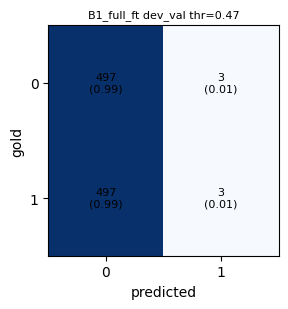

[B1_full_ft] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.47)=0.3386 | test_pos_rate=0.014 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/B1_full_ft/submission.zip


{'name': 'B1_full_ft',
 'technique': 'full fine-tuning',
 'trainable_params': 76752130,
 'total_params': 76752130,
 'n_layers': 8,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 5531,
 'devval_infer_sec': 52.2,
 'peak_gb': 2.55,
 'best_epoch': 1,
 'test_pos_rate': 0.014,
 'notes': '',
 'time': '2026-10-21 04:25',
 'devval_F1@0.5': 0.3333,
 'devval_F1_tuned': 0.3386,
 'thr': 0.47,
 'P': 0.5,
 'R': 0.5,
 'acc': 0.5,
 'F1_c0': 0.6653,
 'F1_c1': 0.0119}

In [ ]:
# B1) full fine-tuning (kept in memory as KD teacher)
run("B1_full_ft", "full fine-tuning", {"method": "full", **REP}, keep=True)

[B2_partial_top3] method=partial view=T0,T1 pool=concat trainable=19.84M / total=76.75M | AMP=True
{"epoch": 1, "train_loss": 0.6954, "sec": 776.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.4, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6929, "sec": 768.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6953, "sec": 769.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 770.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


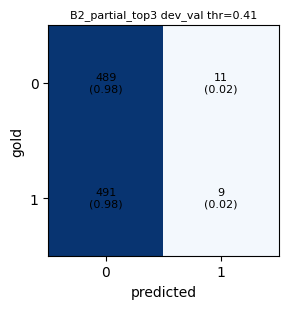

[B2_partial_top3] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.41)=0.3477 | test_pos_rate=0.032 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/B2_partial_top3/submission.zip


{'name': 'B2_partial_top3',
 'technique': 'partial fine-tuning (top 3 blocks)',
 'trainable_params': 19841026,
 'total_params': 76752130,
 'n_layers': 8,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 3210,
 'devval_infer_sec': 52.4,
 'peak_gb': 2.34,
 'best_epoch': 1,
 'test_pos_rate': 0.032,
 'notes': '',
 'time': '2026-10-21 05:21',
 'devval_F1@0.5': 0.3333,
 'devval_F1_tuned': 0.3477,
 'thr': 0.41,
 'P': 0.4745,
 'R': 0.498,
 'acc': 0.498,
 'F1_c0': 0.6608,
 'F1_c1': 0.0346}

In [ ]:
# B2) partial fine-tuning: top-3 blocks + final LayerNorm (frozen lower blocks run under no_grad -> much cheaper)
run("B2_partial_top3", "partial fine-tuning (top 3 blocks)", {"method": "partial", "unfreeze_top": 3, **REP})

[B3_lorma] method=lorma view=T0,T1 pool=concat trainable=1.53M / total=77.49M | AMP=True
{"epoch": 1, "train_loss": 0.6942, "sec": 1380.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 2, "train_loss": 0.6924, "sec": 1362.5, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6956, "sec": 1363.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1368.5, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


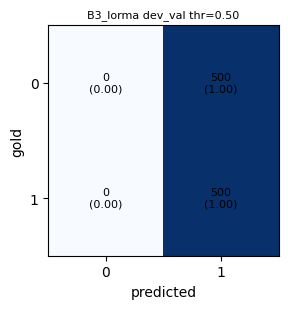

[B3_lorma] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=1.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/B3_lorma/submission.zip


{'name': 'B3_lorma',
 'technique': 'LoRMA+ (multiplicative low-rank, additive inflation)',
 'trainable_params': 1529602,
 'total_params': 77489410,
 'n_layers': 8,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 5609,
 'devval_infer_sec': 55.9,
 'peak_gb': 2.18,
 'best_epoch': 1,
 'test_pos_rate': 1.0,
 'notes': '',
 'time': '2026-10-21 06:57',
 'devval_F1@0.5': 0.3333,
 'devval_F1_tuned': 0.3333,
 'thr': 0.5,
 'P': 0.25,
 'R': 0.5,
 'acc': 0.5,
 'F1_c0': 0.0,
 'F1_c1': 0.6667}

In [ ]:
# B3) LoRMA+ (compulsory)  -- PEFT usually needs a higher LR; if loss is flat after epoch 1, raise lr_adapter to 1e-3
run("B3_lorma", "LoRMA+ (multiplicative low-rank, additive inflation)", {"method": "lorma", **REP})

[B4_adapter] method=adapter view=T0,T1 pool=concat trainable=2.38M / total=78.34M | AMP=True
{"epoch": 1, "train_loss": 0.6949, "sec": 1235.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6926, "sec": 1225.5, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6953, "sec": 1221.5, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1225.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


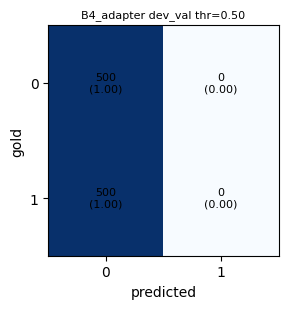

[B4_adapter] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=0.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/B4_adapter/submission.zip


{'name': 'B4_adapter',
 'technique': 'Houlsby bottleneck adapters (dim 64)',
 'trainable_params': 2378498,
 'total_params': 78338306,
 'n_layers': 8,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 5036,
 'devval_infer_sec': 52.7,
 'peak_gb': 2.19,
 'best_epoch': 1,
 'test_pos_rate': 0.0,
 'notes': '',
 'time': '2026-10-21 08:23',
 'devval_F1@0.5': 0.3333,
 'devval_F1_tuned': 0.3333,
 'thr': 0.5,
 'P': 0.25,
 'R': 0.5,
 'acc': 0.5,
 'F1_c0': 0.6667,
 'F1_c1': 0.0}

In [ ]:
# B4) Houlsby bottleneck adapters (after attn.out_proj and ffn.3)
run("B4_adapter", "Houlsby bottleneck adapters (dim 64)", {"method": "adapter", **REP})

[B5_bitfit] method=bitfit view=T0,T1 pool=concat trainable=0.84M / total=76.75M | AMP=True
{"epoch": 1, "train_loss": 0.6948, "sec": 1221.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 2, "train_loss": 0.6925, "sec": 1209.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6953, "sec": 1208.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1210.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


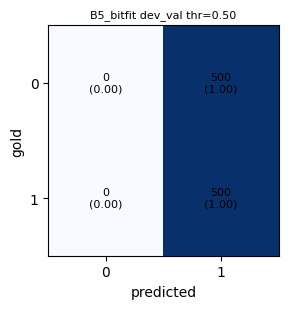

[B5_bitfit] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=1.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/B5_bitfit/submission.zip


{'name': 'B5_bitfit',
 'technique': 'BitFit (biases only)',
 'trainable_params': 836098,
 'total_params': 76752130,
 'n_layers': 8,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 4975,
 'devval_infer_sec': 52.0,
 'peak_gb': 2.17,
 'best_epoch': 1,
 'test_pos_rate': 1.0,
 'notes': '',
 'time': '2026-10-21 09:48',
 'devval_F1@0.5': 0.3333,
 'devval_F1_tuned': 0.3333,
 'thr': 0.5,
 'P': 0.25,
 'R': 0.5,
 'acc': 0.5,
 'F1_c0': 0.0,
 'F1_c1': 0.6667}

In [ ]:
# B5) true BitFit (ffn.0/ffn.3 biases + norm1/norm2/final_norm biases; attention projections are bias-free)
run("B5_bitfit", "BitFit (biases only)", {"method": "bitfit", "lr_adapter": 1e-3, **REP})

student blocks: [0, 2, 5, 7]
[B6_kd_student] method=full view=T0,T1 pool=concat trainable=51.36M / total=51.36M | AMP=True
{"epoch": 1, "train_loss": 0.3531, "sec": 1077.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.47, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.3472, "sec": 1070.5, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.48, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.3492, "sec": 1070.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.48, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.3479, "sec": 1069.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.48, "dev_acc": 0.4867}
early stop


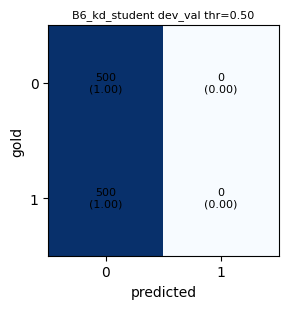

[B6_kd_student] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=0.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/B6_kd_student/submission.zip
[B6b_student_no_kd] method=full view=T0,T1 pool=concat trainable=51.36M / total=51.36M | AMP=True
{"epoch": 1, "train_loss": 0.6957, "sec": 689.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6924, "sec": 679.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6953, "sec": 681.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 682.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


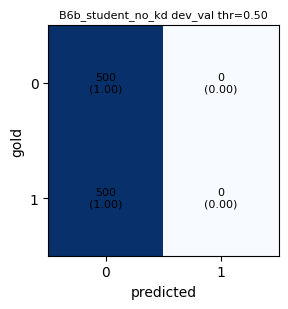

[B6b_student_no_kd] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=0.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/B6b_student_no_kd/submission.zip


{'name': 'B6b_student_no_kd',
 'technique': '4-block layer-strided student, hard labels only (KD ablation)',
 'trainable_params': 51355906,
 'total_params': 51355906,
 'n_layers': 4,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 2799,
 'devval_infer_sec': 26.4,
 'peak_gb': 2.5,
 'best_epoch': 1,
 'test_pos_rate': 0.0,
 'notes': '',
 'time': '2026-10-21 11:49',
 'devval_F1@0.5': 0.3333,
 'devval_F1_tuned': 0.3333,
 'thr': 0.5,
 'P': 0.25,
 'R': 0.5,
 'acc': 0.5,
 'F1_c0': 0.6667,
 'F1_c1': 0.0}

In [ ]:
# B6) knowledge distillation: teacher = B1 (8 blocks) -> student = layer-strided 4 blocks [0, 2, 5, 7] of the Phase-1 model.
#     Loss = CE + KL(logits) + cosine(window features)   (both backbones are d=768, so features are directly comparable)
teacher = get_teacher("B1_full_ft")
print("student blocks:", pick_layers(len(txl.blocks), 4))
run("B6_kd_student", "KD: 8-block teacher -> 4-block layer-strided student", {"method": "full", **REP}, n_layers=4, teacher=teacher, notes="teacher=B1_full_ft; student blocks [0,2,5,7]")
run("B6b_student_no_kd", "4-block layer-strided student, hard labels only (KD ablation)", {"method": "full", **REP}, n_layers=4)

[X1_gradual] method=gradual view=T0,T1 pool=concat trainable=51.59M / total=76.75M | AMP=True
{"epoch": 1, "train_loss": 0.6941, "sec": 430.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6925, "sec": 656.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6955, "sec": 884.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.45, "dev_acc": 0.4867}
{"epoch": 4, "train_loss": 0.6937, "sec": 1111.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 5, "train_loss": 0.6927, "sec": 1348.2, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 6, "train_loss": 0.693, "sec": 1350.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}


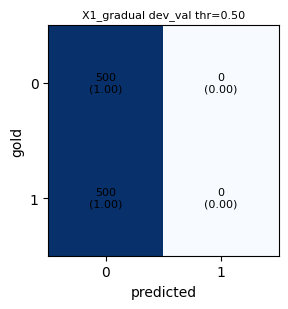

[X1_gradual] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=0.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/X1_gradual/submission.zip
[X2_lora] method=lora view=T0,T1 pool=concat trainable=1.60M / total=77.56M | AMP=True
{"epoch": 1, "train_loss": 0.7001, "sec": 1392.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6925, "sec": 1374.7, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6953, "sec": 1374.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1376.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


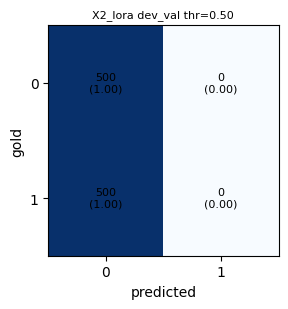

[X2_lora] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=0.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/X2_lora/submission.zip
[X3_rslora] method=rslora view=T0,T1 pool=concat trainable=2.41M / total=78.37M | AMP=True
{"epoch": 1, "train_loss": 0.6983, "sec": 1388.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.46, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6924, "sec": 1365.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6953, "sec": 1365.1, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1369.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


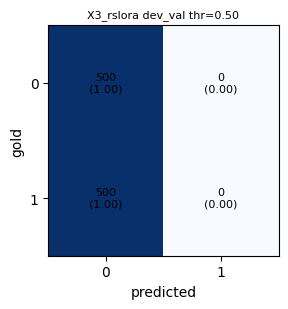

[X3_rslora] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=0.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/X3_rslora/submission.zip
[X4_ia3] method=ia3 view=T0,T1 pool=concat trainable=0.82M / total=76.78M | AMP=True
{"epoch": 1, "train_loss": 0.6948, "sec": 1317.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 2, "train_loss": 0.6929, "sec": 1304.7, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6956, "sec": 1306.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1308.8, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


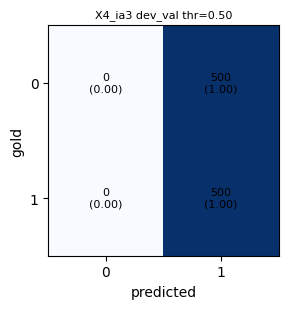

[X4_ia3] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=1.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/X4_ia3/submission.zip
[X5_prompt] method=prompt view=T0,T1 pool=concat trainable=0.80M / total=76.76M | AMP=True
{"epoch": 1, "train_loss": 0.6949, "sec": 1386.0, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3392, "thr": 0.49, "dev_acc": 0.4867}
{"epoch": 2, "train_loss": 0.6924, "sec": 1377.9, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 3, "train_loss": 0.6954, "sec": 1373.6, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1375.7, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
early stop


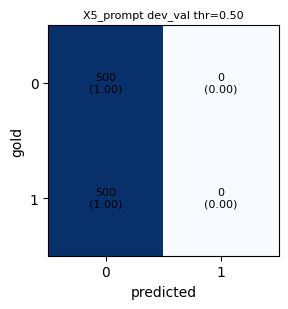

[X5_prompt] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.50)=0.3333 | test_pos_rate=0.0 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/X5_prompt/submission.zip
[X6_prefix] method=prefix view=T0,T1 pool=concat trainable=0.89M / total=76.85M | AMP=True
{"epoch": 1, "train_loss": 0.6953, "sec": 1329.7, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 2, "train_loss": 0.6932, "sec": 1315.3, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3274, "dev_F1_tuned": 0.3584, "thr": 0.48, "dev_acc": 0.4867}
{"epoch": 3, "train_loss": 0.6957, "sec": 1313.2, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 4, "train_loss": 0.6936, "sec": 1316.4, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc": 0.5133}
{"epoch": 5, "train_loss": 0.6927, "sec": 1326.2, "skipped_nonfinite": 0, "dev_F1@0.5": 0.3392, "dev_F1_tuned": 0.3392, "thr": 0.5, "dev_acc

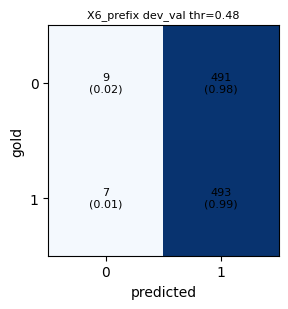

[X6_prefix] dev_val macro-F1 @0.5=0.3333 | tuned(thr=0.48)=0.3497 | test_pos_rate=0.976 | /content/drive/MyDrive/Phase4_CJPE_TXL/experiments/X6_prefix/submission.zip


{'name': 'X6_prefix',
 'technique': 'prefix tuning (16 virtual memory slots / layer, via Transformer-XL memory)',
 'trainable_params': 890626,
 'total_params': 76850434,
 'n_layers': 8,
 'view': 'T0,T1',
 'pool': 'concat',
 'train_sec': 6770,
 'devval_infer_sec': 56.0,
 'peak_gb': 2.24,
 'best_epoch': 2,
 'test_pos_rate': 0.976,
 'notes': '',
 'time': '2026-10-21 21:47',
 'devval_F1@0.5': 0.3333,
 'devval_F1_tuned': 0.3497,
 'thr': 0.48,
 'P': 0.5318,
 'R': 0.502,
 'acc': 0.502,
 'F1_c0': 0.0349,
 'F1_c1': 0.6644}

In [ ]:
# Extras (optional, only if time remains): gradual unfreezing, LoRA, rsLoRA, IA3, prompt tuning, prefix tuning (Transformer-XL memory slot)
run("X1_gradual", "gradual layer-wise unfreezing (+2 blocks/epoch)", {"method": "gradual", "epochs": 6, "patience": 6, **REP})
run("X2_lora", "LoRA r=8", {"method": "lora", **REP})
run("X3_rslora", "rsLoRA r=16", {"method": "rslora", "r": 16, **REP})
run("X4_ia3", "IA3 (K, V, FFN hidden)", {"method": "ia3", "lr_adapter": 1e-3, **REP})
run("X5_prompt", "prompt tuning (16 soft tokens)", {"method": "prompt", "lr_adapter": 1e-3, **REP})
run("X6_prefix", "prefix tuning (16 virtual memory slots / layer, via Transformer-XL memory)", {"method": "prefix", "lr_adapter": 1e-3, **REP})

### Part A – which windows matter? (representation study; use a cheap method such as partial FT with a small budget, e.g. `docs_per_epoch=4000, epochs=3`)

In [ ]:
cheap = {"method": "partial", "unfreeze_top": 3, "docs_per_epoch": 4000, "epochs": 3}
for nm, v, w, pl in [("A1_T0", "T0", 512, "last"), ("A2_T0T1", "T0,T1", 512, "concat"), ("A3_T0T1T2", "T0,T1,T2", 512, "concat"),
                     ("A4_H0T0", "H0,T0", 512, "concat"), ("A5_T0_256", "T0", 256, "last")]:
    run(nm, f"view study | {v} | win {w} | pool {pl} (partial FT)", {**cheap, "view": v, "win_len": w, "pool": pl})

## 10. Error analysis hooks and summary

In [ ]:
def error_by_length(name, q=4):
    df = pd.read_csv(os.path.join(OUTPUT_DIR, "experiments", name, "dev_val_preds.csv")); df["len_bin"] = pd.qcut(df["n_tok"], q, duplicates="drop")
    f = lambda g: pd.Series({"n": len(g), "acc": (g.y == g.pred).mean(), "FP": ((g.y == 0) & (g.pred == 1)).sum(), "FN": ((g.y == 1) & (g.pred == 0)).sum(), "frac_1": g.y.mean()})
    return df.groupby("len_bin", observed=True).apply(f).round(3)
reg = pd.DataFrame(registry)
cols = [c for c in ["name", "technique", "trainable_params", "total_params", "devval_F1@0.5", "devval_F1_tuned", "thr", "P", "R", "F1_c0", "F1_c1", "train_sec", "devval_infer_sec", "peak_gb", "test_pos_rate", "view"] if c in reg.columns]
reg[cols]

## Notes / limitations (put these in your report, in your own words)
* `devval_F1_tuned` uses a threshold fitted on the same `dev_val` it is reported on, so it is mildly optimistic; `devval_F1@0.5` is the stricter number. `dev_val` (1 000 docs) is small: differences of ~1–2 points are noise.
* Dev docs (other than the hold-out) are used for training, repeated `DEV_REPEAT`×. Test never touches training or threshold selection.
* Documents are trimmed to first 2 048 + last 6 144 tokens; windows beyond the chosen `view` are never seen. Report this.
* Windows are encoded **independently**; Transformer-XL's segment-level recurrence (memory) is not used for the classifier (only prefix tuning uses the `memory` slot, with learned content rather than cached states). Report this, and the fact that it is a possible extension.
* The hyper-parameters in `BASE_CFG` are inherited from the GQLA notebook, not tuned for Transformer-XL (post-LN, d=768). Decide and justify your own.
* LoRMA+ is implemented as `y = (I + s·B·A) W0 x + b0` in output space (A kaiming-initialised, B zero ⇒ identity at start); check the formulation against the paper / official code before describing it.
* fp16 autocast is enabled only if `check_amp()` passes; otherwise runs in fp32 (slower).
* Cite: Dai et al. 2019 (Transformer-XL), Ainslie et al. 2023 (GQA), Hu et al. 2021 (LoRA), Kalajdzievski 2023 (rsLoRA), Bihany et al. 2025 (LoRMA), Houlsby et al. 2019, Ben Zaken et al. 2022 (BitFit), Liu et al. 2022 (IA³), Li & Liang 2021 (prefix tuning), Lester et al. 2021 (prompt tuning), Hinton et al. 2015, Chen et al. 2016 (checkpointing), Malik et al. 2021 (ILDC), and your Phase-1 model.